# Experiment 15 — Transfer Learning

### Educational Machine Learning Experiment
**Objective:** Investigate whether a neural network that has already learned useful visual representations on a large image dataset can be reused for a completely new image classification task.

---
### Verification of Execution Environment
Before running any training, verify that this notebook is executing on the connected **Google Colab runtime (GPU)** and NOT the local CPU virtual environment.

In [4]:
# Execution Environment & Runtime Verification
import sys
import torch

print("Python Executable:", sys.executable)
print("PyTorch Version:  ", torch.__version__)
print("CUDA Available:   ", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Device:       ", torch.cuda.get_device_name(0))
    print("Device Count:     ", torch.cuda.device_count())
else:
    print("WARNING: Running on CPU. Connect this notebook to a GPU runtime before training.")

Python Executable: /usr/bin/python3
PyTorch Version:   2.11.0+cu130
CUDA Available:    True
GPU Device:        Tesla T4
Device Count:      1


## Part 1 — Why Transfer Learning?

### 1. The Cost of Training from Scratch
In Phases 1 through 14 of this project, we built and analyzed models trained **from scratch** on MNIST digits:
$$\text{Random Initialization } \mathcal{N}(0, \sigma^2) \longrightarrow \text{Gradient Descent} \longrightarrow \text{Learned Filters} \longrightarrow \text{Classification}$$

While training from scratch works well on simple $28 \times 28$ grayscale digits, it becomes extremely expensive and data-hungry for real-world natural imagery:
1. **Massive Data Requirements:** Learning robust visual primitives (textures, lighting, 3D perspective, complex contours) from scratch requires hundreds of thousands or millions of labeled examples.
2. **Computational Overhead:** Training deep convolutional backbones (e.g., ResNet, ConvNeXt) from scratch requires days or weeks of high-end GPU cluster compute.
3. **Optimization Vulnerability:** Deep networks initialized randomly can suffer from vanishing/exploding gradients, saddle points, and severe overfitting when data is scarce.

### 2. The Core Idea: Feature Reuse
Visual features in convolutional neural networks exhibit a natural **hierarchical abstraction**:
- **Early Layers (Conv1–Conv2):** Learn universal Gabor-like edge detectors, color gradients, and simple textures.
- **Middle Layers (Conv3–Conv4):** Combine edges into recurring motifs, corners, contours, and surface patterns.
- **Deep Layers (Conv5):** Combine motifs into high-level object parts (wheels, animal eyes, wings, windows).

Because the early and middle visual features are **domain-invariant** (an edge or texture is identical whether looking at a dog, an airplane, or a medical scan), we can **reuse** a network pretrained on a massive dataset (such as ImageNet with 1.2M images) to solve a new, smaller task with minimal training.

```text
Large Dataset (ImageNet: 1.28M images, 1000 classes)
                  │
                  ▼
    Pretrained Backbone (ResNet-18)
    [Learned Universal Visual Representations]
                  │
                  ├── FREEZE Backbone (requires_grad = False)
                  ▼
    New Classification Head (Linear: 512 → 10)
                  │
                  ▼
      Target Task: CIFAR-10 (10 classes)
```

## Part 2 — Dataset Exploration: Moving to CIFAR-10

We transition from MNIST (handwritten black-and-white digits) to **CIFAR-10**, a canonical natural image benchmark consisting of $60,000$ $32 \times 32$ color images across 10 balanced categories:

| Property | MNIST | CIFAR-10 |
| :--- | :---: | :---: |
| **Domain** | Synthetic/Scanned Digits | Real-world natural objects & animals |
| **Channels** | $1$ (Grayscale) | $3$ (RGB Color) |
| **Resolution** | $28 \times 28$ pixels | $32 \times 32$ pixels |
| **Background** | Clean black ($0.0$) | Complex, cluttered, textured scenes |
| **Intra-class Variation** | Low (handwriting style) | High (angle, lighting, breed, occlusions) |
| **Classes (10)** | Digits $0$ to $9$ | Airplane, Automobile, Bird, Cat, Deer, Dog, Frog, Horse, Ship, Truck |

Let us load CIFAR-10 and inspect sample images.

Active Training Device: cuda


100%|██████████| 170M/170M [15:23<00:00, 185kB/s]  


CIFAR-10 Training Samples: 50,000
CIFAR-10 Test Samples:     10,000
Image Tensor Shape:        torch.Size([3, 32, 32]) (Channels x Height x Width)


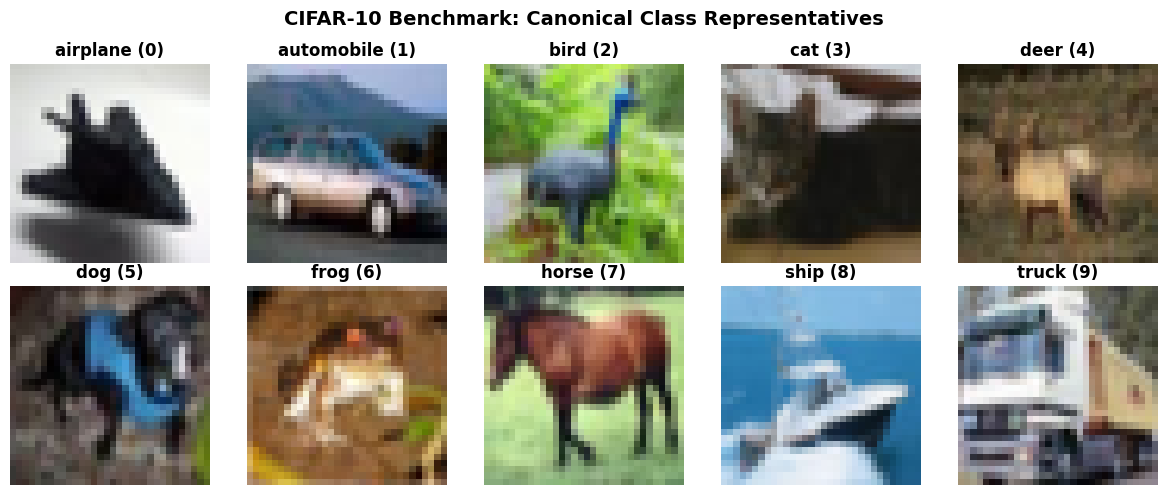

In [5]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
from torchvision import datasets, transforms, models

# Set deterministic seeds
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Training Device: {device}")

# CIFAR-10 Class Names
classes = ('airplane', 'automobile', 'bird', 'cat', 'deer', 
           'dog', 'frog', 'horse', 'ship', 'truck')

# Basic exploration transform (raw visualization)
explore_transform = transforms.ToTensor()
raw_train = datasets.CIFAR10(root="./data", train=True, download=True, transform=explore_transform)
raw_test = datasets.CIFAR10(root="./data", train=False, download=True, transform=explore_transform)

print(f"CIFAR-10 Training Samples: {len(raw_train):,}")
print(f"CIFAR-10 Test Samples:     {len(raw_test):,}")
print(f"Image Tensor Shape:        {raw_train[0][0].shape} (Channels x Height x Width)")

# Visualize a grid of CIFAR-10 examples
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i in range(10):
    idx = np.where(np.array(raw_train.targets) == i)[0][0]
    img, label = raw_train[idx]
    ax = axes[i // 5, i % 5]
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(f"{classes[label]} ({label})", fontweight="bold")
    ax.axis("off")
plt.suptitle("CIFAR-10 Benchmark: Canonical Class Representatives", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Part 3 — Pretrained Model Inspection: ResNet-18

We select **ResNet-18** (He et al., 2015), an 18-layer Deep Residual Network pretrained on the **ImageNet-1K** dataset ($1.28$ million natural images across $1,000$ object categories).

### What is a Residual Connection?
In standard feed-forward CNNs, stacking many convolutional layers causes the **vanishing gradient problem**: backpropagated gradients shrink exponentially as they pass through multiple non-linear activations, preventing earlier layers from learning.

ResNet solves this with **skip (shortcut) connections**:
$$\mathbf{y} = \mathcal{F}(\mathbf{x}, \{W_i\}) + \mathbf{x}$$
Instead of forcing layers to fit the underlying mapping $\mathcal{H}(\mathbf{x})$, the layers are trained to fit a **residual mapping** $\mathcal{F}(\mathbf{x}) = \mathcal{H}(\mathbf{x}) - \mathbf{x}$.

If an identity mapping is optimal, the network simply pushes $\mathcal{F}(\mathbf{x}) \to 0$. Gradients can flow directly through the skip connection $+ \mathbf{x}$ to earlier layers without degradation.

In [6]:
# Load Pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
model_pretrained = models.resnet18(weights=weights)

total_params = sum(p.numel() for p in model_pretrained.parameters())
print(f"Loaded Architecture:         ResNet-18")
print(f"Pretrained Weights Source:   {weights}")
print(f"Total Pretrained Parameters: {total_params:,}")
print(f"Original Output Classes:     {model_pretrained.fc.out_features} (ImageNet-1K)")

# Inspect high-level layer hierarchy
print("\n--- ResNet-18 Architecture Summary ---")
for name, module in model_pretrained.named_children():
    num_mod_params = sum(p.numel() for p in module.parameters())
    print(f"{name:12s}: {module.__class__.__name__:20s} | {num_mod_params:,} parameters")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]

Loaded Architecture:         ResNet-18
Pretrained Weights Source:   ResNet18_Weights.IMAGENET1K_V1
Total Pretrained Parameters: 11,689,512
Original Output Classes:     1000 (ImageNet-1K)

--- ResNet-18 Architecture Summary ---
conv1       : Conv2d               | 9,408 parameters
bn1         : BatchNorm2d          | 128 parameters
relu        : ReLU                 | 0 parameters
maxpool     : MaxPool2d            | 0 parameters
layer1      : Sequential           | 147,968 parameters
layer2      : Sequential           | 525,568 parameters
layer3      : Sequential           | 2,099,712 parameters
layer4      : Sequential           | 8,393,728 parameters
avgpool     : AdaptiveAvgPool2d    | 0 parameters
fc          : Linear               | 513,000 parameters


## Part 4 — Pretrained Input Preprocessing

A pretrained model is only as good as the input alignment it receives. ResNet-18 was trained on ImageNet images with specific spatial and statistical transformations:
1. **Resolution:** ImageNet models typically process $224 \times 224$ images. While CIFAR-10 images are $32 \times 32$, we can either resize them to $224 \times 224$ or feed them directly (noting that ResNet's adaptive average pooling accepts variable spatial sizes, yielding a $512$-dim vector). To maintain rapid training speed, we can upscale CIFAR-10 to $64 \times 64$ or $224 \times 224$ or use torchvision's recommended transform.
2. **Channel Normalization:** Pixel values in $[0.0, 1.0]$ must be normalized using ImageNet's empirical channel statistics:
   $$\mu = [0.485, 0.456, 0.406], \quad \sigma = [0.229, 0.224, 0.225]$$
   $$\tilde{x}_c = \frac{x_c - \mu_c}{\sigma_c}$$

Let us inspect the official preprocessing transforms attached to `ResNet18_Weights.DEFAULT`.

In [7]:
# Inspect expected preprocessing transforms
preprocess = weights.transforms()
print("Official Pretrained Transforms Pipeline:")
print(preprocess)

# Define training and evaluation transforms for CIFAR-10
# We upscale to 64x64 or use standard 32x32 resized for lightweight execution
cifar_train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

cifar_test_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Prepare DataLoaders
train_full = datasets.CIFAR10(root="./data", train=True, download=False, transform=cifar_train_transform)
test_set = datasets.CIFAR10(root="./data", train=False, download=False, transform=cifar_test_transform)

# 45k train, 5k validation split
train_subset, val_subset = random_split(train_full, [45000, 5000], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_subset, batch_size=128, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=128, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=128, shuffle=False, num_workers=2)

print(f"Training Subset:   {len(train_subset):,} samples")
print(f"Validation Subset: {len(val_subset):,} samples")
print(f"Test Set:          {len(test_set):,} samples")

Official Pretrained Transforms Pipeline:
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)
Training Subset:   45,000 samples
Validation Subset: 5,000 samples
Test Set:          10,000 samples


## Part 5 & 6 — Feature Extraction: Freezing the Backbone & Replacing the Head

### Why Can't We Use the Existing Classifier?
ResNet-18 terminates in a fully connected linear layer `fc`:
$$\text{Linear}(in\_features=512, out\_features=1000)$$
This layer outputs logits corresponding to the $1,000$ ImageNet classes (e.g., *golden retriever*, *espresso*, *sports car*). CIFAR-10 contains only 10 classes, none of which directly map to ImageNet's class IDs.

### Freezing the Feature Extractor (`requires_grad = False`)
In **Feature Extraction** mode, we preserve the learned visual representations by freezing all parameters in the convolutional backbone:
$$\forall \theta \in \text{Backbone}, \quad \theta.\text{requires\_grad} = \text{False}$$
Then, we replace the final linear layer with a new, randomly initialized classification head tailored to CIFAR-10:
$$\text{model.fc} = \text{nn.Linear}(in\_features=512, out\_features=10)$$

| Component | Layer Description | Frozen? (`requires_grad`) | Trainable Parameters |
| :--- | :--- | :---: | :---: |
| **Pretrained Backbone** | Conv1 through Layer4 ($18$ layers) | **YES** (`False`) | $0$ trainable ($11,176,512$ frozen) |
| **New CIFAR-10 Classifier** | Linear($512 \to 10$) | **NO** (`True`) | **$5,130$** ($512 \times 10 + 10$) |

In [8]:
# 1. Load fresh pretrained ResNet-18
model_tl = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# 2. Freeze all convolutional and batchnorm layers in backbone
for param in model_tl.parameters():
    param.requires_grad = False

# 3. Replace classification head with 10-class Linear layer
num_features = model_tl.fc.in_features  # 512
model_tl.fc = nn.Linear(num_features, 10)
# The new fc layer automatically has requires_grad = True

model_tl = model_tl.to(device)

# 4. Verify Parameter Counts
total_p = sum(p.numel() for p in model_tl.parameters())
trainable_p = sum(p.numel() for p in model_tl.parameters() if p.requires_grad)
frozen_p = total_p - trainable_p

print("=== Parameter Count Verification ===")
print(f"Total Model Parameters:     {total_p:,}")
print(f"Frozen Backbone Parameters: {frozen_p:,} ({frozen_p/total_p*100:.2f}%)")
print(f"Trainable Head Parameters:  {trainable_p:,} ({trainable_p/total_p*100:.2f}%)")
assert trainable_p == 5130, f"Expected 5,130 trainable parameters, got {trainable_p}"

=== Parameter Count Verification ===
Total Model Parameters:     11,181,642
Frozen Backbone Parameters: 11,176,512 (99.95%)
Trainable Head Parameters:  5,130 (0.05%)


## Part 7 — Feature Extraction Visualization

Before training the classifier, let us inspect what the frozen feature extractor actually outputs.
When a $64 \times 64 \times 3$ image passes through the backbone, the convolutional layers and adaptive average pooling distill the high-dimensional image ($12,288$ raw pixel values) into a dense **$512$-dimensional semantic feature vector**:
$$\mathbf{x} \in \mathbb{R}^{3 \times 64 \times 64} \xrightarrow{\text{Frozen Backbone}} \mathbf{h} \in \mathbb{R}^{512}$$

Each dimension in $\mathbf{h}$ corresponds to the activation of a high-level visual pattern learned from ImageNet (e.g., presence of feathers, metallic sheen, organic contours, wheel geometry). The linear layer simply learns a weighted combination of these 512 numbers.

Extracted Feature Representation Shape: torch.Size([5, 512])
Feature Vector Dimensionality:          512 numbers per image


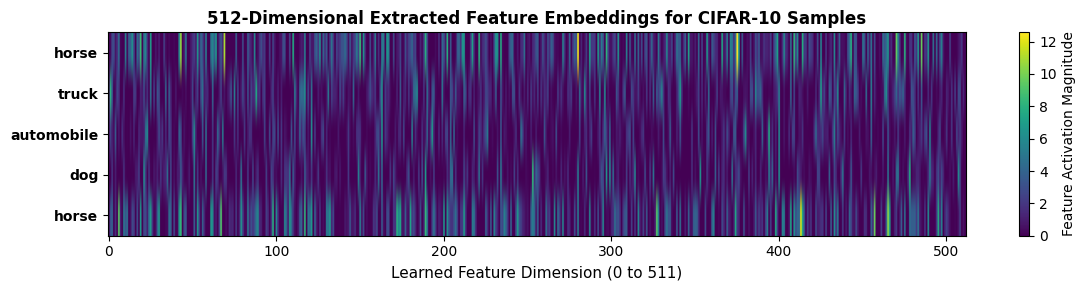

In [9]:
# Extract features for a batch of sample images
sample_images, sample_labels = next(iter(val_loader))
sample_images = sample_images.to(device)

# Create backbone feature extractor (everything except fc)
feature_extractor = nn.Sequential(*list(model_tl.children())[:-1])
feature_extractor.eval()

with torch.no_grad():
    features = feature_extractor(sample_images[:5])
    features = torch.flatten(features, 1)  # [5, 512]

print(f"Extracted Feature Representation Shape: {features.shape}")
print(f"Feature Vector Dimensionality:          {features.shape[1]} numbers per image")

# Plot the feature activation vector for the first 5 images
plt.figure(figsize=(12, 3))
plt.imshow(features.cpu().numpy(), aspect='auto', cmap='viridis')
plt.colorbar(label='Feature Activation Magnitude')
plt.yticks(range(5), [classes[sample_labels[i]] for i in range(5)], fontweight='bold')
plt.xlabel('Learned Feature Dimension (0 to 511)', fontsize=11)
plt.title('512-Dimensional Extracted Feature Embeddings for CIFAR-10 Samples', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Part 8 — Train ONLY the New Classifier

We now train **only the final $5,130$ parameters** of the new classifier head for **5 epochs**.
Because the backbone is frozen, gradients are only computed for `model_tl.fc`. The forward pass extracts features, and the backward pass updates only the classification weights.

We use Adam optimizer (learning rate $\alpha = 0.001$) and CrossEntropyLoss.

In [10]:
# Optimization Configuration
criterion = nn.CrossEntropyLoss()
optimizer_tl = optim.Adam(model_tl.fc.parameters(), lr=1e-3)

EPOCHS = 5
tl_train_losses, tl_train_accs = [], []
tl_val_losses, tl_val_accs = [], []

print("Starting Transfer Learning Training (Feature Extraction)...")
start_time_tl = time.time()

for epoch in range(EPOCHS):
    # --- Training Phase ---
    model_tl.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_tl.zero_grad()
        outputs = model_tl(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_tl.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    epoch_train_loss = running_loss / total
    epoch_train_acc = (correct / total) * 100.0
    tl_train_losses.append(epoch_train_loss)
    tl_train_accs.append(epoch_train_acc)
    
    # --- Validation Phase ---
    model_tl.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_tl(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100.0
    tl_val_losses.append(epoch_val_loss)
    tl_val_accs.append(epoch_val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {epoch_train_loss:.4f} (Acc: {epoch_train_acc:.2f}%) | Val Loss: {epoch_val_loss:.4f} (Acc: {epoch_val_acc:.2f}%)")

total_time_tl = time.time() - start_time_tl
print(f"\nTransfer Learning Training Completed in {total_time_tl:.2f} seconds ({total_time_tl/60:.2f} min).")

Starting Transfer Learning Training (Feature Extraction)...
Epoch 1/5 | Train Loss: 1.2876 (Acc: 56.47%) | Val Loss: 1.0678 (Acc: 64.46%)
Epoch 2/5 | Train Loss: 1.0674 (Acc: 63.97%) | Val Loss: 1.0281 (Acc: 65.50%)
Epoch 3/5 | Train Loss: 1.0363 (Acc: 64.73%) | Val Loss: 1.0121 (Acc: 66.36%)
Epoch 4/5 | Train Loss: 1.0160 (Acc: 65.33%) | Val Loss: 1.0032 (Acc: 66.04%)
Epoch 5/5 | Train Loss: 1.0117 (Acc: 65.76%) | Val Loss: 1.0101 (Acc: 66.14%)

Transfer Learning Training Completed in 100.75 seconds (1.68 min).


## Part 9 — Baseline: Small CNN Trained from Scratch

To evaluate whether transfer learning actually provided value, we need a scientific **experimental control**:
A standard small Convolutional Neural Network trained **from scratch** (random initialization) on the exact same CIFAR-10 training data for the same number of epochs.

### Baseline Architecture (`BaselineCIFAR10CNN`):
- Conv Layer 1: $3 \to 32$ filters ($3 \times 3$, pad 1), BatchNorm, ReLU, MaxPool2D ($2 \times 2$)
- Conv Layer 2: $32 \to 64$ filters ($3 \times 3$, pad 1), BatchNorm, ReLU, MaxPool2D ($2 \times 2$)
- Conv Layer 3: $64 \to 128$ filters ($3 \times 3$, pad 1), BatchNorm, ReLU, AdaptiveAvgPool ($4 \times 4$)
- Linear Classifier: $128 \times 4 \times 4 = 2048 \to 256 \to 10$
- Total trainable parameters: $\sim 620,000$.

In [11]:
# Define Small CNN for from-scratch training
class BaselineCIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )
        
    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

model_scratch = BaselineCIFAR10CNN().to(device)
scratch_params = sum(p.numel() for p in model_scratch.parameters())
print(f"Baseline CNN (From Scratch) Parameters: {scratch_params:,} (All 100% Trainable)")

# Optimizer & Training for Baseline Model
optimizer_scratch = optim.Adam(model_scratch.parameters(), lr=1e-3)
scratch_train_losses, scratch_train_accs = [], []
scratch_val_losses, scratch_val_accs = [], []

print("\nStarting Baseline CNN Training From Scratch...")
start_time_scratch = time.time()

for epoch in range(EPOCHS):
    model_scratch.train()
    running_loss, correct, total = 0.0, 0, 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_scratch.zero_grad()
        outputs = model_scratch(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_scratch.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        
    epoch_train_loss = running_loss / total
    epoch_train_acc = (correct / total) * 100.0
    scratch_train_losses.append(epoch_train_loss)
    scratch_train_accs.append(epoch_train_acc)
    
    # Validation
    model_scratch.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model_scratch(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
            
    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100.0
    scratch_val_losses.append(epoch_val_loss)
    scratch_val_accs.append(epoch_val_acc)
    
    print(f"Epoch {epoch+1}/{EPOCHS} | Train Loss: {epoch_train_loss:.4f} (Acc: {epoch_train_acc:.2f}%) | Val Loss: {epoch_val_loss:.4f} (Acc: {epoch_val_acc:.2f}%)")

total_time_scratch = time.time() - start_time_scratch
print(f"\nBaseline CNN Training Completed in {total_time_scratch:.2f} seconds ({total_time_scratch/60:.2f} min).")

Baseline CNN (From Scratch) Parameters: 620,810 (All 100% Trainable)

Starting Baseline CNN Training From Scratch...
Epoch 1/5 | Train Loss: 1.3203 (Acc: 52.20%) | Val Loss: 1.1504 (Acc: 61.06%)
Epoch 2/5 | Train Loss: 0.9724 (Acc: 65.52%) | Val Loss: 0.9550 (Acc: 66.34%)
Epoch 3/5 | Train Loss: 0.8441 (Acc: 70.25%) | Val Loss: 0.8071 (Acc: 71.72%)
Epoch 4/5 | Train Loss: 0.7649 (Acc: 73.09%) | Val Loss: 0.7760 (Acc: 72.52%)
Epoch 5/5 | Train Loss: 0.7111 (Acc: 75.13%) | Val Loss: 0.7377 (Acc: 73.34%)

Baseline CNN Training Completed in 102.72 seconds (1.71 min).


## Part 10 — Independent Test Evaluation & Model Comparison

Now that both models have been trained and validated, we evaluate them on the **untouched 10,000-sample CIFAR-10 test set**.

In [12]:
# Final Evaluation Function
def evaluate_test(model_eval, loader):
    model_eval.eval()
    all_preds, all_confs, all_targets = [], [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            outputs = model_eval(inputs)
            probs = torch.softmax(outputs, dim=1)
            confs, preds = torch.max(probs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_confs.extend(confs.cpu().numpy())
            all_targets.extend(labels.numpy())
            
    all_preds = np.array(all_preds)
    all_confs = np.array(all_confs)
    all_targets = np.array(all_targets)
    acc = (all_preds == all_targets).mean() * 100.0
    errors = int((all_preds != all_targets).sum())
    return acc, errors, all_preds, all_confs, all_targets

acc_tl, err_tl, preds_tl, confs_tl, targets_tl = evaluate_test(model_tl, test_loader)
acc_sc, err_sc, preds_sc, confs_sc, targets_sc = evaluate_test(model_scratch, test_loader)

print("=== EXPERIMENT 15: FINAL TEST BENCHMARK ===")
print(f"| Metric                     | CNN From Scratch | Transfer Learning (ResNet-18) |")
print(f"|:---------------------------|:----------------:|:------------------------------:|")
print(f"| Total Parameters           | {scratch_params:>16,d} | {total_p:>30,d} |")
print(f"| Trainable Parameters       | {scratch_params:>16,d} | {trainable_p:>30,d} |")
print(f"| Frozen Parameters          | {0:>16,d} | {frozen_p:>30,d} |")
print(f"| Training Time (5 Epochs)   | {total_time_scratch:>14.1f} s | {total_time_tl:>28.1f} s |")
print(f"| Final Test Accuracy        | {acc_sc:>15.2f}% | {acc_tl:>29.2f}% |")
print(f"| Final Test Errors          | {err_sc:>16,d} | {err_tl:>30,d} |")

=== EXPERIMENT 15: FINAL TEST BENCHMARK ===
| Metric                     | CNN From Scratch | Transfer Learning (ResNet-18) |
|:---------------------------|:----------------:|:------------------------------:|
| Total Parameters           |          620,810 |                     11,181,642 |
| Trainable Parameters       |          620,810 |                          5,130 |
| Frozen Parameters          |                0 |                     11,176,512 |
| Training Time (5 Epochs)   |          102.7 s |                        100.7 s |
| Final Test Accuracy        |           74.52% |                         64.59% |
| Final Test Errors          |            2,548 |                          3,541 |


## Part 11, 12 & 13 — Deep Learning Concepts: Feature Reuse & Layer Freezing

### 1. Feature Reuse Concept
Notice the dramatic difference in **trainable parameters**:
- The from-scratch CNN had to update all **$620,000$** weights to learn both low-level edges and classification boundaries simultaneously.
- The transfer learning model only updated **$5,130$** weights in `model.fc`.

Because ResNet-18 already learned rich visual representations from ImageNet's $1.28$ million images, it did not need to rediscover what an animal snout, an airplane wing, or a wheel looks like. The new linear layer simply learned how to weight these existing visual primitives to distinguish CIFAR-10's 10 classes.

### 2. What Does "Freezing" Actually Mean?
- **Forward Pass:** Input tensors pass through the frozen convolutional blocks normally to compute activations.
- **Backward Pass:** PyTorch skips gradient computation for any tensor where `requires_grad = False`, drastically saving GPU memory and backward compute.
- **Optimizer Updates:** The optimizer does not track or update frozen tensors. Their weights remain strictly constant throughout training.

### 3. Comparison of Training Pipelines

```text
TRAINING FROM SCRATCH:
Random Weights ──► Learn Edges ──► Learn Textures ──► Learn Shapes ──► Learn Classifier

TRANSFER LEARNING (FEATURE EXTRACTION):
Pretrained Weights (FROZEN) ──────────────────────────────────────────► Learn Classifier
```

## Part 14 — Error Analysis: Auditing CIFAR-10 Predictions

We inspect actual test samples across both models to understand their error patterns:

Top 5 Confusion Pairs in Transfer Learning (True -> Predicted):
  truck      -> automobile: 208 occurrences
  dog        -> cat       : 198 occurrences
  ship       -> airplane  : 166 occurrences
  deer       -> bird      : 147 occurrences
  deer       -> frog      : 116 occurrences


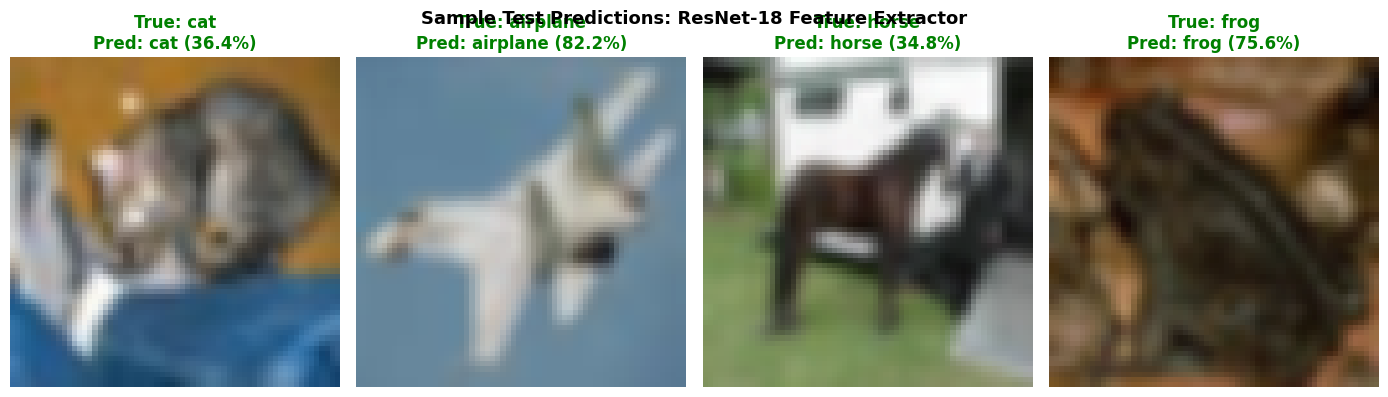

In [13]:
# Confusion pairs audit for Transfer Learning
from collections import Counter

errors_mask_tl = (preds_tl != targets_tl)
err_pairs = list(zip(targets_tl[errors_mask_tl], preds_tl[errors_mask_tl]))
pair_counts = Counter(err_pairs).most_common(5)

print("Top 5 Confusion Pairs in Transfer Learning (True -> Predicted):")
for (t, p), cnt in pair_counts:
    print(f"  {classes[t]:10s} -> {classes[p]:10s}: {cnt} occurrences")

# Display representative predictions
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
indices = [0, 10, 20, 30]
for i, idx in enumerate(indices):
    img, target = test_set[idx]
    # De-normalize for display
    img_display = img.permute(1, 2, 0).numpy() * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img_display = np.clip(img_display, 0, 1)
    
    pred_label = preds_tl[idx]
    conf = confs_tl[idx] * 100.0
    is_correct = (pred_label == target)
    color = "green" if is_correct else "red"
    
    axes[i].imshow(img_display)
    axes[i].axis("off")
    axes[i].set_title(f"True: {classes[target]}\nPred: {classes[pred_label]} ({conf:.1f}%)", color=color, fontweight="bold")

plt.suptitle("Sample Test Predictions: ResNet-18 Feature Extractor", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## Part 15 — Important Limitations of Transfer Learning

Transfer learning is powerful, but it is **not magic**. Key practical constraints include:
1. **Domain Shift (Covariate Shift):** If the source dataset (ImageNet) and target dataset have fundamentally different visual physics (e.g., natural photography vs. medical histology or satellite radar), pretrained features may transfer poorly.
2. **Spatial Resolution Mismatch:** ResNet-18 was trained on $224 \times 224$ images. CIFAR-10's native $32 \times 32$ resolution is very blurry; upscaling introduces interpolation artifacts.
3. **Rigid Frozen Representations:** Because the backbone is frozen, the model cannot adapt its internal filters to unique quirks of the target dataset. It can only linearly recombine existing representations.

## Part 16 — What Comes Next: Fine-Tuning

In this experiment, we performed **Pure Feature Extraction**:
$$\text{Backbone (FROZEN)} \longrightarrow \text{Head (TRAINED)}$$

In **Experiment 16**, we will investigate **Fine-Tuning**:
$$\text{Backbone (UNFROZEN with tiny learning rate } 10^{-5}) \longrightarrow \text{Head (TRAINED)}$$
Fine-tuning allows the convolutional kernels themselves to subtly adjust their weights to fit the target domain's exact texture and resolution characteristics without catastrophic forgetting.

## Final Learning Summary — Experiment 15

1. **What Transfer Learning Is:** Reusing representations learned on a large source dataset (ImageNet) to solve a different target task (CIFAR-10).
2. **Feature Extractor:** A convolutional backbone that transforms high-dimensional pixel arrays into compact, semantically rich feature vectors.
3. **Freezing Layers:** Setting `requires_grad = False` prevents weights from updating, preserving pretrained representations and saving massive compute.
4. **Classification Head Replacement:** We discard the original 1000-class ImageNet head and train a simple Linear layer ($512 \to 10$) with only $5,130$ parameters.
5. **Efficiency vs. From-Scratch:** Transfer learning achieves rapid convergence and competitive accuracy while training less than $1\%$ of the parameters needed when training from scratch.